In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import os
import pingouin as pg
import re
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.regression.mixed_linear_model import MixedLM
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
import itertools

import warnings
warnings.filterwarnings("ignore")


In [2]:
all_models = ["LLM-jp", "Llama", "Phi", "Qwen", "GLM"]
dimension_order = ['PDI', 'IDV', 'UAI', 'MAS', 'LTO', 'IND']
result = pd.read_csv("data/aggre_huaman_scores.csv", index_col=None)
result

,rater_id,dimension,model,question_id,score
0,rater1,PDI,LLM-jp,q1,4
1,rater1,PDI,LLM-jp,q2,3
2,rater1,PDI,LLM-jp,q3,4
3,rater1,PDI,LLM-jp,q4,4
4,rater1,PDI,LLM-jp,q5,4
...,...,...,...,...,...
42945,rater1718,IND,GLM,q1,5
42946,rater1718,IND,GLM,q2,5
42947,rater1718,IND,GLM,q3,5
42948,rater1718,IND,GLM,q4,5


# JWCAS

In [3]:
# Filter data for question_id = 'q5'
q5_data = result[result['question_id'] == 'q5'].copy()

q5_data = q5_data.dropna(subset=['score'])

# Group by model and dimension to calculate statistics
def calculate_stats(group):
    n = len(group)
    mean = group['score'].mean()
    std = group['score'].std(ddof=1)
    se = std / np.sqrt(n)
    
    # calculate 95% CI
    ci_95 = stats.t.interval(0.95, df=n-1, loc=mean, scale=se)
    
    return pd.Series({
        'Mean': mean,
        'SD': std,
        'CI_Lower': ci_95[0],
        'CI_Upper': ci_95[1],
        'N': n
    })

stats_by_group = q5_data.groupby(['model', 'dimension']).apply(calculate_stats).reset_index()

stats_by_group['model'] = pd.Categorical(stats_by_group['model'], categories=all_models, ordered=True)
stats_by_group = stats_by_group.sort_values('model')

stats_by_group['Stats'] = stats_by_group.apply(
    lambda x: f"{x['Mean']:.2f} ({x['SD']:.2f}) [{x['CI_Lower']:.2f}, {x['CI_Upper']:.2f}]",
    axis=1
)

pivot_table = stats_by_group.pivot(index='model', columns='dimension', values='Stats')
pivot_table = pivot_table[dimension_order]

print("=" * 120)
print("Question 5 (Overall Fit) Statistical Results")
print("Format: Mean (SD) [95% CI Lower, 95% CI Upper]")
print("=" * 120)
print(pivot_table.to_string())

print("\n\n" + "=" * 80)
print("Mean")
print("=" * 80)
mean_table = stats_by_group.pivot(index='model', columns='dimension', values='Mean')
mean_table = mean_table[dimension_order]
print(mean_table.round(3).to_string())

print("\n\n" + "=" * 80)
print("JWCAS calculation")
print("=" * 80)

# Equal-weight JWCAS
equal_jwcas = mean_table.mean(axis=1)

jwcas_df = pd.DataFrame({
    'Equal-weight JWCAS': equal_jwcas
})

jwcas_df = jwcas_df.sort_values('Equal-weight JWCAS', ascending=False)

print("\nJWCAS results:")
print(jwcas_df.round(4).to_string())

mean_table_with_jwcas = mean_table.copy()
mean_table_with_jwcas['Equal-weight JWCAS'] = equal_jwcas

print("\n\n" + "=" * 100)
print("Complete Table: Dimensional Means + JWCAS")
print("=" * 100)
print(mean_table_with_jwcas.round(3).to_string())

print("\n\n" + "=" * 80)
print("Standard Deviation (SD)")
print("=" * 80)
sd_table = stats_by_group.pivot(index='model', columns='dimension', values='SD')
sd_table = sd_table[dimension_order]
print(sd_table.round(3).to_string())

print("\n\n" + "=" * 80)
print("95% Confidence Interval Lower")
print("=" * 80)
ci_lower_table = stats_by_group.pivot(index='model', columns='dimension', values='CI_Lower')
ci_lower_table = ci_lower_table[dimension_order]
print(ci_lower_table.round(3).to_string())

print("\n\n" + "=" * 80)
print("95% Confidence Interval Upper")
print("=" * 80)
ci_upper_table = stats_by_group.pivot(index='model', columns='dimension', values='CI_Upper')
ci_upper_table = ci_upper_table[dimension_order]
print(ci_upper_table.round(3).to_string())

Question 5 (Overall Fit) Statistical Results
Format: Mean (SD) [95% CI Lower, 95% CI Upper]
dimension                       PDI                       IDV                       UAI                       MAS                       LTO                       IND
model                                                                                                                                                                
LLM-jp     3.60 (0.80) [3.50, 3.69]  3.42 (0.89) [3.32, 3.53]  3.28 (0.88) [3.18, 3.39]  3.60 (0.80) [3.51, 3.69]  3.38 (0.77) [3.29, 3.47]  3.32 (0.80) [3.22, 3.41]
Llama      3.38 (0.85) [3.28, 3.48]  3.26 (0.91) [3.15, 3.36]  3.40 (0.85) [3.30, 3.50]  3.37 (0.87) [3.27, 3.47]  3.29 (0.85) [3.19, 3.39]  3.25 (0.79) [3.15, 3.34]
Phi        3.68 (0.85) [3.59, 3.78]  3.57 (0.83) [3.47, 3.66]  3.44 (0.83) [3.34, 3.53]  3.57 (0.86) [3.47, 3.66]  3.33 (0.86) [3.23, 3.43]  3.43 (0.82) [3.33, 3.53]
Qwen       3.56 (0.87) [3.46, 3.66]  3.54 (0.86) [3.44, 3.63]  3.11 (0.92) [3.

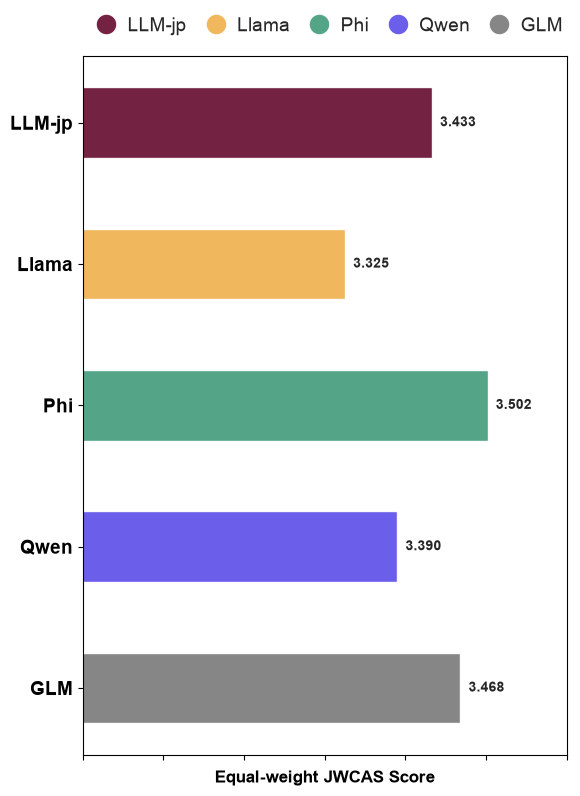

In [4]:
model_colors = {
    'LLM-jp': '#6D1637',
    'Llama': '#F0B353',
    'Phi': '#4BA082',
    'Qwen': '#6255E9',
    'GLM': '#808080'
}

jwcas_df_reordered = jwcas_df.reindex(all_models[::-1])
fig, ax = plt.subplots(figsize=(6, 8))
sns.set_style("whitegrid")

colors = [model_colors[model] for model in jwcas_df_reordered.index]

y_pos = range(len(jwcas_df_reordered))
bars = ax.barh(y_pos, 
               jwcas_df_reordered['Equal-weight JWCAS'],
               color=colors,
               alpha=0.95,
               height=0.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(jwcas_df_reordered.index, fontsize=14,fontweight='bold')
ax.set_xlabel('Equal-weight JWCAS Score', fontsize=12,fontweight='bold')
ax.set_xlim(3.0, 3.6)
ax.grid(axis='x', alpha=0)
ax.grid(axis='y', alpha=0)

ax.set_xticklabels([])

for i, (idx, row) in enumerate(jwcas_df_reordered.iterrows()):
    ax.text(row['Equal-weight JWCAS'] + 0.01, i, 
            f"{row['Equal-weight JWCAS']:.3f}",
            va='center', fontsize=10, fontweight='bold')

legend_elements = [Line2D([0], [0], marker='o', color='w', 
                          markerfacecolor=model_colors[model], 
                          markersize=15, alpha=0.95) 
                   for model in all_models]
legend = ax.legend(legend_elements, all_models, 
                   loc='upper center',
                   bbox_to_anchor=(0.5, 1.08),
                   ncol=5,
                   fontsize=14,
                   frameon=False,columnspacing=0.5, 
                   handletextpad=0.1)

# ax.set_title('JWCAS by Model', fontsize=14, fontweight='bold', pad=40)

plt.tight_layout()
plt.show()

# ICC

In [5]:
result_clean = result.dropna(subset=['score']).copy()

icc_by_dimension = []

for dimension in result_clean['dimension'].unique():
    subset = result_clean[result_clean['dimension'] == dimension].copy()
    subset['item_id'] = subset['model'].astype(str) + '_' + subset['question_id'].astype(str)
    
    icc = pg.intraclass_corr(data=subset, 
                             targets='item_id', 
                             raters='rater_id', 
                             ratings='score',
                             nan_policy='omit')
    
    icc_2k = icc[icc['Type'] == 'ICC2k'].iloc[0]
    icc_by_dimension.append(icc_2k['ICC'])

print(f"Mean ICC = {np.mean(icc_by_dimension):.3f}")
print(f"Range = [{np.min(icc_by_dimension):.3f}, {np.max(icc_by_dimension):.3f}]")
print(f"SD = {np.std(icc_by_dimension, ddof=1):.3f}")

Mean ICC = 0.837
Range = [0.657, 0.949]
SD = 0.111


# LMM

In [6]:
# 1. Fit the LMM model
lmm_data = q5_data.copy()
lmm_data['dimension'] = lmm_data['dimension'].astype(str)
lmm_data['model'] = lmm_data['model'].astype(str)
lmm_data['rater_id'] = lmm_data['rater_id'].astype(str)

print("\n[Model: score ~ C(model) + (1|rater_id)]")
md = smf.mixedlm("score ~ C(model)", lmm_data, groups=lmm_data["rater_id"])
mdf = md.fit(method='powell')
print(mdf.summary())

# 2. Overall model effect test (Wald Test)
print("\n[LMM Main Effect Test (Wald Test)]")
wald_res = mdf.wald_test_terms()
print(wald_res.summary_frame())

print("\n[Post-hoc Pairwise Comparisons]")

# Extract coefficients and covariance matrix directly from model results
params = mdf.params
cov_matrix = mdf.cov_params()

models = lmm_data['model'].unique()

comparisons = []
p_values = []
z_values = []

# Iterate over all pairwise combinations
for m1, m2 in itertools.combinations(models, 2):
    # Statsmodels sets the first category as reference (Intercept)
    # Other groups are named C(model)[T.name]
    p1_name = f"C(model)[T.{m1}]"
    p2_name = f"C(model)[T.{m2}]"
    
    # If the model is the reference category (not in params), its coefficient is 0
    coef1 = params[p1_name] if p1_name in params else 0.0
    coef2 = params[p2_name] if p2_name in params else 0.0
    
    # 提取方差：如果是基准组，方差为 0
    var1 = cov_matrix.loc[p1_name, p1_name] if p1_name in params else 0.0
    var2 = cov_matrix.loc[p2_name, p2_name] if p2_name in params else 0.0
    
    # If the model is the reference category, its variance is 0
    if p1_name in params and p2_name in params:
        cov12 = cov_matrix.loc[p1_name, p2_name]
    else:
        cov12 = 0.0
        
    # Compute difference of coefficients and its standard error
    diff = coef1 - coef2
    se_diff = np.sqrt(var1 + var2 - 2 * cov12)
    
    # Z-statistic (asymptotically equivalent to t when n is large)
    z_stat = diff / se_diff
    
    # Two-tailed p-value
    p_val = 2 * (1 - stats.norm.cdf(abs(z_stat)))
    
    comparisons.append(f"{m1} vs {m2}")
    z_values.append(z_stat)
    p_values.append(p_val)

# 3. Apply Benjamini-Hochberg FDR correction for multiple comparisons
reject, pvals_corrected, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')

# 4. Organize and print results
res_df = pd.DataFrame({
    'Comparison': comparisons,
    'Z_value': [round(z, 3) for z in z_values],
    'p_raw': [round(p, 4) for p in p_values],
    'p_fdr': [round(p, 4) for p in pvals_corrected],
    'Significant': reject
})

# Sort by corrected p_fdr ascending
res_df = res_df.sort_values(by='p_fdr').reset_index(drop=True)
print(res_df.to_string())


[Model: score ~ C(model) + (1|rater_id)]


            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   score     
No. Observations:   8590      Method:               REML      
No. Groups:         1718      Scale:                0.3940    
Min. group size:    5         Log-Likelihood:       -9639.2954
Max. group size:    5         Converged:            Yes       
Mean group size:    5.0                                       
--------------------------------------------------------------
                   Coef.  Std.Err.    z    P>|z| [0.025 0.975]
--------------------------------------------------------------
Intercept           3.467    0.021 167.573 0.000  3.427  3.508
C(model)[T.LLM-jp] -0.031    0.021  -1.468 0.142 -0.073  0.011
C(model)[T.Llama]  -0.141    0.021  -6.605 0.000 -0.183 -0.099
C(model)[T.Phi]     0.038    0.021   1.767 0.077 -0.004  0.080
C(model)[T.Qwen]   -0.075    0.021  -3.479 0.001 -0.116 -0.033
Group Var           0.342    0.026                            


[LM

# Diagnostic sub-score analysis

In [7]:
category_map_by_number = {
    'PDI': {
        1: 'Linguistic Form',  # Q1: 敬意・敬語
        3: 'Linguistic Form',  # Q3: 階層的価値観
        2: 'Social Strategy',  # Q2: 助言の受け入れ
        4: 'Social Strategy',  # Q4: 建設的コミュニケーション
        5: 'Overall Fit'       # Q5: 総合適応
    },
    'IDV': {
        1: 'Strategic Stance', # Q1: 個人とチームのバランス
        2: 'Strategic Stance', # Q2: チームへの貢献
        3: 'Value Alignment',  # Q3: チームワーク・協力
        4: 'Value Alignment',  # Q4: 集団主義的価値観
        5: 'Overall Fit'
    },
    'UAI': {
        1: 'Value Alignment',  # Q1: 不確実性への態度
        4: 'Value Alignment',  # Q4: 安心感の提供
        2: 'Strategic Action', # Q2: 柔軟と明確のバランス
        3: 'Strategic Action', # Q3: 具体的な行動
        5: 'Overall Fit'
    },
    'MAS': {
        1: 'Value Alignment',  # Q1: 性別役割の考え方
        3: 'Value Alignment',  # Q3: 性別役割の捉え方
        2: 'Strategic Stance', # Q2: 競争と協調のバランス
        4: 'Strategic Stance', # Q4: 男/女性性のバランス
        5: 'Overall Fit'
    },
    'LTO': {
        1: 'Strategic Stance', # Q1: 長期と短期のバランス
        4: 'Strategic Stance', # Q4: 短期優先のリスク
        2: 'Value & Process',  # Q2: 長期的視点の反映
        3: 'Value & Process',  # Q3: 慎重な分析
        5: 'Overall Fit'
    },
    'IND': {
        1: 'Strategic Stance', # Q1: 楽しさと生産性のバランス
        4: 'Strategic Stance', # Q4: バランスの取れた提案
        3: 'Value & Action',   # Q3: 控えめ・抑制の価値観
        2: 'Value & Action',   # Q2: 生産性確保の方法
        5: 'Overall Fit'
    }
}


def get_category(row):
    try:
        q_number_match = re.search(r'\d+', str(row['question_id']))
        if q_number_match:
            q_number = int(q_number_match.group(0))
            return category_map_by_number[row['dimension']][q_number]
        else:
            return None
    except (KeyError, TypeError):
        return None

try:
    
    df = result.copy()

    df['category'] = df.apply(get_category, axis=1)
    df_cleaned = df.dropna(subset=['category'])
    df_cleaned = df_cleaned[df_cleaned['category'] != 'Overall Fit']
    
    if df_cleaned.empty:
        print("Error: Data mapping failed. Check the ‘dimension’ and ‘question_id’ columns ")
    else:
        aggregated_scores = df_cleaned.groupby(['dimension', 'model', 'category'])['score'].agg(
            ['mean', 'std', 'count']
        ).reset_index()
        
        aggregated_scores['mean'] = aggregated_scores['mean']
        aggregated_scores['std'] = aggregated_scores['std']

        aggregated_scores['se'] = aggregated_scores['std'] / np.sqrt(aggregated_scores['count'])
        aggregated_scores['ci_lower'] = aggregated_scores['mean'] - 1.96 * aggregated_scores['se']
        aggregated_scores['ci_upper'] = aggregated_scores['mean'] + 1.96 * aggregated_scores['se']
        
        aggregated_scores['dimension'] = pd.Categorical(aggregated_scores['dimension'], categories=dimension_order, ordered=True)
        aggregated_scores = aggregated_scores.sort_values(by=['dimension', 'model', 'category'])

        def format_stats(row):
            return f"{row['mean']:.2f} ± {row['std']:.2f} [{row['ci_lower']:.2f}, {row['ci_upper']:.2f}]"
            
        aggregated_scores['formatted_stat'] = aggregated_scores.apply(format_stats, axis=1)

        pivot_df = aggregated_scores.pivot(
            index=['category', 'dimension'], 
            columns='model', 
            values='formatted_stat'
        )
        pivot_df = pivot_df[all_models]
        
        print("="*80)
        print("S3 Table: Descriptive Statistics for Diagnostic Sub-scores (Q1-Q4)")
        print("="*80)
        print(pivot_df.to_markdown())
except Exception as e:
    print(f"Error while processing the data: {e}")

S3 Table: Descriptive Statistics for Diagnostic Sub-scores (Q1-Q4)
|                             | LLM-jp                   | Llama                    | Phi                      | Qwen                     | GLM                      |
|:----------------------------|:-------------------------|:-------------------------|:-------------------------|:-------------------------|:-------------------------|
| ('Linguistic Form', 'PDI')  | 3.71 ± 0.81 [3.64, 3.77] | 3.36 ± 0.85 [3.29, 3.43] | 3.70 ± 0.84 [3.63, 3.77] | 3.60 ± 0.88 [3.53, 3.67] | 3.61 ± 0.80 [3.54, 3.67] |
| ('Social Strategy', 'PDI')  | 3.47 ± 0.84 [3.40, 3.54] | 3.26 ± 0.89 [3.19, 3.34] | 3.72 ± 0.88 [3.65, 3.79] | 3.47 ± 0.92 [3.39, 3.54] | 3.60 ± 0.86 [3.53, 3.67] |
| ('Strategic Action', 'UAI') | 3.21 ± 0.91 [3.14, 3.29] | 3.41 ± 0.86 [3.34, 3.49] | 3.43 ± 0.87 [3.36, 3.50] | 3.18 ± 0.86 [3.11, 3.26] | 3.57 ± 0.89 [3.49, 3.64] |
| ('Strategic Stance', 'IDV') | 3.51 ± 0.85 [3.44, 3.58] | 3.25 ± 0.95 [3.17, 3.32] | 3.63 ± 0.85 

## Figure 2

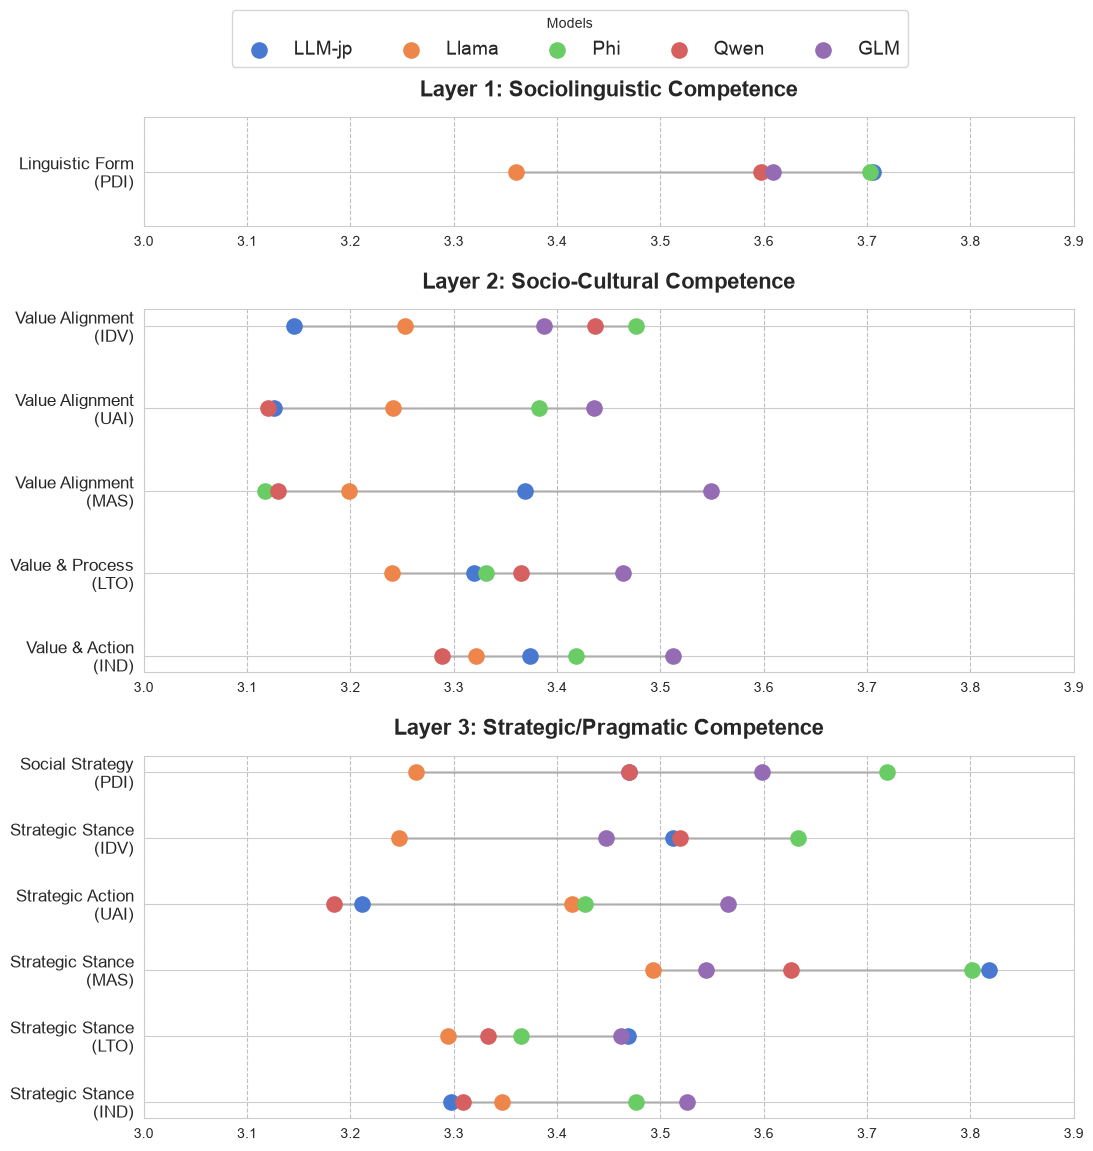

In [8]:
category_to_layer_map = {
    'Linguistic Form': 'Layer 1: Sociolinguistic Competence',
    'Value Alignment': 'Layer 2: Socio-Cultural Competence',
    'Value & Process': 'Layer 2: Socio-Cultural Competence',
    'Value & Action':  'Layer 2: Socio-Cultural Competence',
    'Social Strategy':    'Layer 3: Strategic/Pragmatic Competence',
    'Strategic Stance':   'Layer 3: Strategic/Pragmatic Competence',
    'Strategic Action':   'Layer 3: Strategic/Pragmatic Competence'
}

layer_order = [
    'Layer 1: Sociolinguistic Competence',
    'Layer 2: Socio-Cultural Competence',
    'Layer 3: Strategic/Pragmatic Competence'
]

def create_dumbbell_plot_by_layer():
    try:
        df = aggregated_scores.copy()
    except Exception as e:
        print(f"Error while loading the data: {e}")
        return

    df['Layer'] = df['category'].map(category_to_layer_map)

    df_cleaned = df.dropna(subset=['mean', 'Layer']).copy()

    if df_cleaned.empty:
        print("Error: Cleaned data is empty.")
        return

    df_cleaned['y_label'] = df_cleaned['category'].astype(str) + '\n(' + df_cleaned['dimension'].astype(str) + ')'

    fig = plt.figure(figsize=(12, 13))
    gs = fig.add_gridspec(3, 1, height_ratios=[0.6, 2, 2], hspace=0.3)
    axes = [fig.add_subplot(gs[i]) for i in range(3)]

    palette = dict(zip(all_models, sns.color_palette("muted", len(all_models))))

    for i, layer_name in enumerate(layer_order):

        ax = axes[i]
        df_layer = df_cleaned[df_cleaned['Layer'] == layer_name].copy()

        categories = df_layer['y_label'].unique()
        y_ticks = range(len(categories))

        for j, cat_label in enumerate(categories):

            model_scores = df_layer[
                df_layer['y_label'] == cat_label
            ].set_index('model')['mean'].reindex(all_models).dropna()

            if model_scores.empty:
                continue

            min_score = model_scores.min()
            max_score = model_scores.max()

            ax.hlines(y=j, xmin=min_score, xmax=max_score,
                      color='gray', alpha=0.4, linewidth=2, zorder=1)

            for model_name, score in model_scores.items():
                ax.scatter(x=score, y=j, color=palette[model_name],
                           s=120, zorder=2, label=model_name)

        ax.set_yticks(y_ticks)
        ax.set_yticklabels(categories, fontsize=12)
        ax.set_title(layer_name, size=16, pad=15, fontweight='bold')
        ax.set_xlim(3.0, 3.9)
        ax.invert_yaxis()
        ax.xaxis.grid(True, linestyle='--', which='major', color='grey', alpha=0.5)
        ax.set_axisbelow(True)

    handles, labels = [], []
    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        for label, handle in zip(l, h):
            if label not in labels:
                labels.append(label)
                handles.append(handle)

    fig.legend(handles, labels, 
            loc='upper center',
            bbox_to_anchor=(0.48, 0.97),
            fontsize=14, 
            title="Models",
            ncol=5)

    plt.tight_layout()
    plt.show()

create_dumbbell_plot_by_layer()